# Task B1: Detecting Fraudulent Job Postings (EMSCAD Dataset)
### AI-101 Machine Learning Assignment | Pool B: Mixed Modality (Tabular + Text)
**Student Name:** Muhammad Zain-ul-Abideen  
**Roll Number:** 70177771  
**Section:** B  
**Instructor:** Dr. Muhammad Awais  
**Institution:** Department of Computer Science, The University of Lahore  
**GitHub Repository:** https://github.com/zainrjzain-code/AI101-ML-Assignment-70177771  

---
### Assignment Objectives for Task B1:
1. **Exploratory Data Analysis (EDA):** Analyze class imbalance (4.8% fraud), missing value patterns, metadata fraud rates (`has_company_logo`, `employment_type`), and text length distributions.
2. **Mixed Modality Feature Engineering:**
   - Structured Features: Binary indicators, missingness signals (`missing_company_profile`), text length/word count statistics, and one-hot encoding of top categories.
   - Text Features: Concatenate text fields (`title`, `company_profile`, `description`, `requirements`, `benefits`) and extract TF-IDF word unigrams and bigrams.
3. **Data Splitting & Zero Leakage:** Stratified 70/15/15 train/validation/test split with fixed random seed (`random_state=42`). Preprocessing pipelines fitted strictly on training data.
4. **Benchmark Model Training:** Logistic Regression, Linear SVM (calibrated), and Random Forest with class weighting.
5. **Threshold Tuning:** Tune classification decision thresholds on the validation set to maximize F1-score on the fraud class.
6. **Mandatory Modality Ablation Study:** Evaluate and compare (i) Structured features only, (ii) Text features only, and (iii) Combined features on the held-out test set.
7. **Error Analysis:** Inspect top predictive fraud indicators and examine misclassified real postings (false positives).


## Step 1: Environment Setup and Library Imports
We configure reproducible random seeds and import required numerical, natural language processing, modeling, and evaluation libraries.


In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    precision_recall_curve, roc_curve, classification_report
)
from scipy.sparse import hstack, csr_matrix

# Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Environment initialized successfully with seed:", RANDOM_SEED)


Environment initialized successfully with seed: 42


## Step 2: Dataset Loading and Initial Inspection
We load the Employment Scam Aegean Dataset (EMSCAD) containing 17,880 real and fraudulent job postings.


In [2]:
csv_path = r"C:\Users\Hp\.gemini\antigravity\scratch\AI101-ML-Assignment-70177771\B1\data\fake_job_postings.csv"
if not os.path.exists(csv_path):
    import urllib.request
    os.makedirs(os.path.dirname(csv_path), exist_ok=True)
    url = "https://raw.githubusercontent.com/l05t0ka/Fraud-Job-Offers-Analysis/master/fake_job_postings.csv"
    urllib.request.urlretrieve(url, csv_path)

df = pd.read_csv(csv_path)
print(f"Dataset Dimensions: {df.shape[0]} rows x {df.shape[1]} columns")
df.head(3)


Dataset Dimensions: 17880 rows x 18 columns


## Step 3: Exploratory Data Analysis (EDA)
### 3.1 Class Imbalance and Missing Value Analysis
We examine the distribution of the target variable (`fraudulent`) and missingness across attributes.


In [3]:
fraud_counts = df['fraudulent'].value_counts()
fraud_rate = df['fraudulent'].mean()

print(f"Non-Fraudulent Postings (0): {fraud_counts[0]:,} ({fraud_counts[0]/len(df)*100:.2f}%)")
print(f"Fraudulent Postings (1):     {fraud_counts[1]:,} ({fraud_counts[1]/len(df)*100:.2f}%)")
print(f"Overall Fraud Rate:          {fraud_rate*100:.2f}%")

missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values('Missing Count', ascending=False)

print("\nMissing Values Summary (Top 10):")
print(missing_summary.head(10))


Non-Fraudulent Postings (0): 17,014 (95.16%)
Fraudulent Postings (1):     866 (4.84%)
Overall Fraud Rate:          4.84%

Missing Values Summary (Top 10):
                     Missing Count  Missing Percentage
salary_range                 15012               83.96
department                   11547               64.58
required_education            8105               45.33
benefits                      7212               40.34
required_experience           7050               39.43
function                      6455               36.10
industry                      4903               27.42
employment_type               3471               19.41
company_profile               3308               18.50
requirements                  2696               15.08


### 3.2 Visualizing Class Imbalance and Attribute Missingness


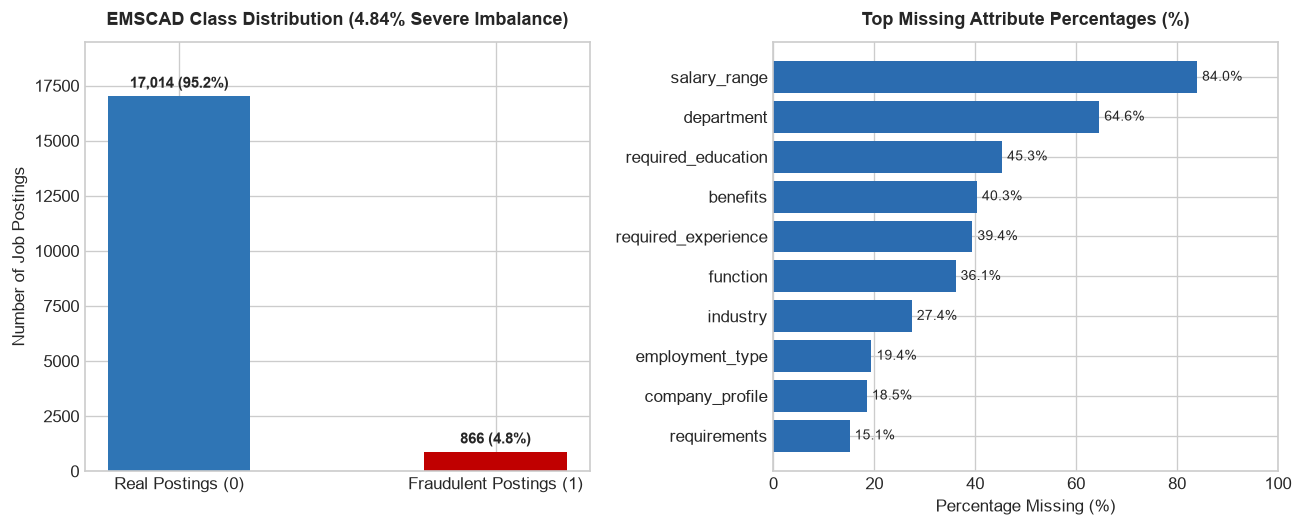

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Class balance
bars = axes[0].bar(['Real Postings (0)', 'Fraudulent Postings (1)'], 
                   [fraud_counts[0], fraud_counts[1]], 
                   color=['#2F75B5', '#C00000'], width=0.45)
axes[0].set_title('EMSCAD Class Distribution (4.84% Severe Imbalance)', fontsize=11, fontweight='bold', pad=10)
axes[0].set_ylabel('Number of Job Postings', fontsize=10)
axes[0].set_ylim(0, 19500)
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 250, f'{yval:,} ({yval/len(df)*100:.1f}%)', 
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

# Missingness
missing_top10 = missing_summary[missing_summary['Missing Count'] > 0].head(10)
axes[1].barh(missing_top10.index, missing_top10['Missing Percentage'], color='#2B6CB0')
axes[1].set_title('Top Missing Attribute Percentages (%)', fontsize=11, fontweight='bold', pad=10)
axes[1].set_xlabel('Percentage Missing (%)', fontsize=10)
axes[1].invert_yaxis()
for i, v in enumerate(missing_top10['Missing Percentage']):
    axes[1].text(v + 1, i, f'{v:.1f}%', va='center', fontsize=8.5)
axes[1].set_xlim(0, 100)

plt.tight_layout()
plt.show()


### 3.3 Fraud Rate by Company Metadata (Logo, Profile Missingness, Employment Type)
Scammers frequently omit legitimate branding or target specific job categories.


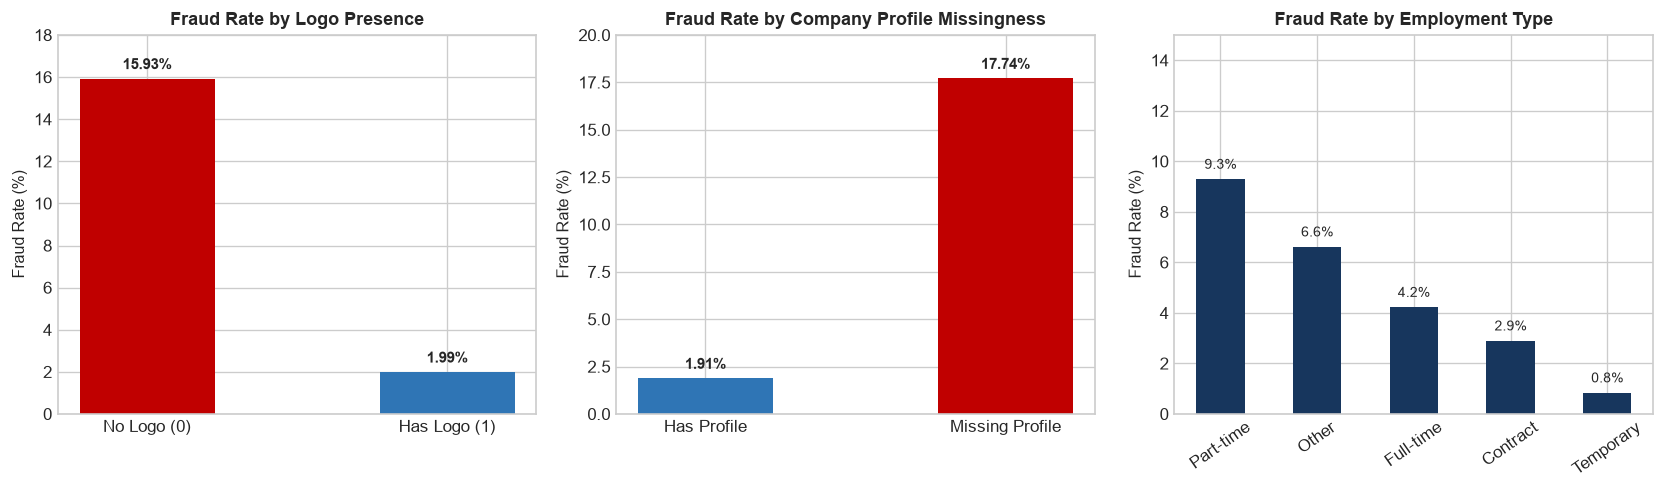

In [5]:
df['missing_company_profile'] = df['company_profile'].isnull().astype(int)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

# Fraud by logo
logo_fraud = df.groupby('has_company_logo')['fraudulent'].mean() * 100
axes[0].bar(['No Logo (0)', 'Has Logo (1)'], logo_fraud.values, color=['#C00000', '#2F75B5'], width=0.45)
axes[0].set_title('Fraud Rate by Logo Presence', fontsize=10.5, fontweight='bold')
axes[0].set_ylabel('Fraud Rate (%)', fontsize=9.5)
axes[0].set_ylim(0, 18)
for i, v in enumerate(logo_fraud.values):
    axes[0].text(i, v + 0.3, f'{v:.2f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

# Fraud by missing company profile
prof_fraud = df.groupby('missing_company_profile')['fraudulent'].mean() * 100
axes[1].bar(['Has Profile', 'Missing Profile'], prof_fraud.values, color=['#2F75B5', '#C00000'], width=0.45)
axes[1].set_title('Fraud Rate by Company Profile Missingness', fontsize=10.5, fontweight='bold')
axes[1].set_ylabel('Fraud Rate (%)', fontsize=9.5)
axes[1].set_ylim(0, 20)
for i, v in enumerate(prof_fraud.values):
    axes[1].text(i, v + 0.3, f'{v:.2f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

# Fraud by employment type
emp_fraud = df.groupby('employment_type')['fraudulent'].mean().sort_values(ascending=False) * 100
axes[2].bar(emp_fraud.index, emp_fraud.values, color='#17365D', width=0.5)
axes[2].set_title('Fraud Rate by Employment Type', fontsize=10.5, fontweight='bold')
axes[2].set_ylabel('Fraud Rate (%)', fontsize=9.5)
axes[2].tick_params(axis='x', rotation=35)
axes[2].set_ylim(0, 15)
for i, v in enumerate(emp_fraud.values):
    axes[2].text(i, v + 0.3, f'{v:.1f}%', ha='center', va='bottom', fontsize=8.5)

plt.tight_layout()
plt.show()


### 3.4 Text Length Distribution Analysis (Real vs Fraudulent)
We analyze differences in word count and character volume between legitimate postings and scams.


Description Word Count Statistics:
Real Mean: 171.04137768896203 | Fraud Mean: 158.74826789838338
Total Word Count Statistics:
Real Mean: 379.4910661807923 | Fraud Mean: 282.3325635103926


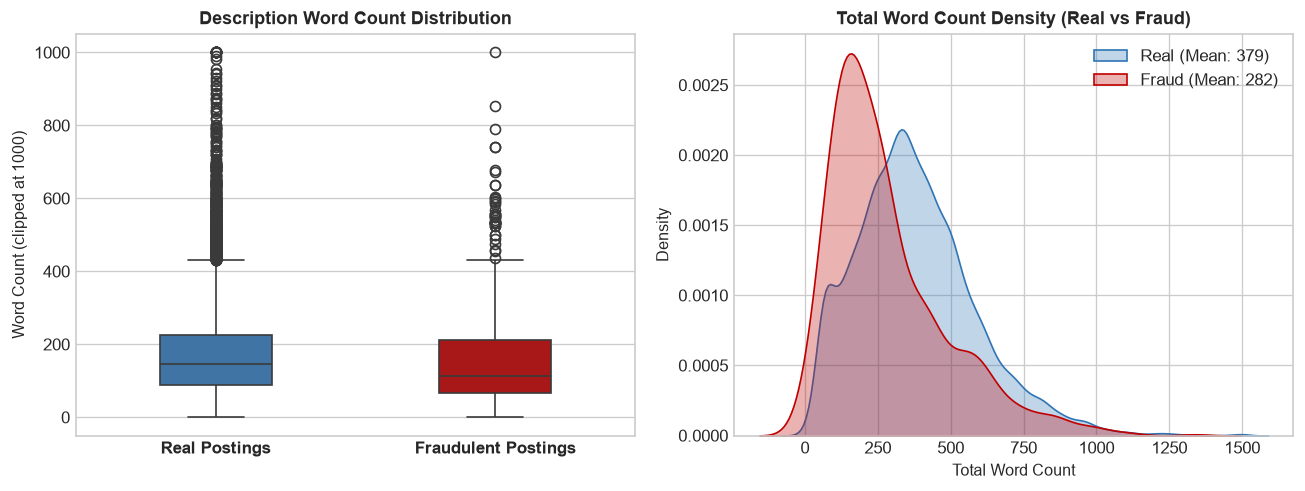

In [6]:
text_cols = ['title', 'company_profile', 'description', 'requirements', 'benefits']
for col in text_cols:
    df[col] = df[col].fillna('')

df['word_count_desc'] = df['description'].apply(lambda s: len(s.split()))
df['word_count_total'] = (df['title'] + " " + df['company_profile'] + " " + df['description'] + " " + df['requirements'] + " " + df['benefits']).apply(lambda s: len(s.split()))

print("Description Word Count Statistics:")
print("Real Mean:", df[df['fraudulent'] == 0]['word_count_desc'].mean(), "| Fraud Mean:", df[df['fraudulent'] == 1]['word_count_desc'].mean())
print("Total Word Count Statistics:")
print("Real Mean:", df[df['fraudulent'] == 0]['word_count_total'].mean(), "| Fraud Mean:", df[df['fraudulent'] == 1]['word_count_total'].mean())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

# Boxplot
df_clip = df.copy()
df_clip['word_count_desc_clipped'] = df_clip['word_count_desc'].clip(upper=1000)
sns.boxplot(x='fraudulent', y='word_count_desc_clipped', data=df_clip, palette=['#2F75B5', '#C00000'], ax=axes[0], width=0.4)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Real Postings', 'Fraudulent Postings'], fontweight='bold')
axes[0].set_title('Description Word Count Distribution', fontsize=10.5, fontweight='bold')
axes[0].set_ylabel('Word Count (clipped at 1000)', fontsize=9.5)
axes[0].set_xlabel('')

# Density
sns.kdeplot(df[df['fraudulent'] == 0]['word_count_total'].clip(upper=1500), ax=axes[1], 
            label='Real (Mean: {:.0f})'.format(df[df['fraudulent'] == 0]['word_count_total'].mean()), 
            color='#2F75B5', fill=True, alpha=0.3)
sns.kdeplot(df[df['fraudulent'] == 1]['word_count_total'].clip(upper=1500), ax=axes[1], 
            label='Fraud (Mean: {:.0f})'.format(df[df['fraudulent'] == 1]['word_count_total'].mean()), 
            color='#C00000', fill=True, alpha=0.3)
axes[1].set_title('Total Word Count Density (Real vs Fraud)', fontsize=10.5, fontweight='bold')
axes[1].set_xlabel('Total Word Count', fontsize=9.5)
axes[1].set_ylabel('Density', fontsize=9.5)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()


## Step 4: Data Splitting and Leakage Prevention
To guarantee rigorous and unbiased evaluation:
1. We split raw samples into **70% Training** (12,516 samples), **15% Validation** (2,682 samples), and **15% Test** (2,682 samples).
2. We apply stratified sampling to maintain the identical 4.84% fraud ratio across all three sets.
3. Preprocessors (TF-IDF vectorizer, standard scalers, one-hot encoders) are **strictly fitted on the training split only**.


In [7]:
# Additional engineered features
df['missing_salary_range'] = df['salary_range'].isnull().astype(int)
df['missing_requirements'] = df['requirements'].isnull().astype(int)
df['missing_benefits'] = df['benefits'].isnull().astype(int)
df['char_count_desc'] = df['description'].apply(len)
df['char_count_total'] = df['title'].apply(len) + df['company_profile'].apply(len) + df['description'].apply(len) + df['requirements'].apply(len) + df['benefits'].apply(len)

df['full_text'] = (
    df['title'] + " " +
    df['company_profile'] + " " +
    df['description'] + " " +
    df['requirements'] + " " +
    df['benefits']
).str.lower().str.replace(r'[^a-zA-Z0-9\s]', ' ', regex=True)

cat_cols = ['employment_type', 'required_experience', 'required_education']
for col in cat_cols:
    df[col] = df[col].fillna('Unspecified')
    top_vals = df[col].value_counts().nlargest(8).index
    df[col] = df[col].apply(lambda x: x if x in top_vals else 'Other')

# Stratified Split
train_val_idx, test_idx = train_test_split(
    np.arange(len(df)), test_size=0.15, stratify=df['fraudulent'], random_state=RANDOM_SEED
)
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=0.15 / (1.0 - 0.15), stratify=df.iloc[train_val_idx]['fraudulent'], random_state=RANDOM_SEED
)

train_df = df.iloc[train_idx].copy().reset_index(drop=True)
val_df = df.iloc[val_idx].copy().reset_index(drop=True)
test_df = df.iloc[test_idx].copy().reset_index(drop=True)

y_train = train_df['fraudulent'].values
y_val = val_df['fraudulent'].values
y_test = test_df['fraudulent'].values

print(f"Training Samples:   {len(train_df):,} | Fraudulent: {np.sum(y_train)} ({np.mean(y_train)*100:.2f}%)")
print(f"Validation Samples: {len(val_df):,} | Fraudulent: {np.sum(y_val)} ({np.mean(y_val)*100:.2f}%)")
print(f"Test Samples:       {len(test_df):,} | Fraudulent: {np.sum(y_test)} ({np.mean(y_test)*100:.2f}%)")


Training Samples:   12,516 | Fraudulent: 606 (4.84%)
Validation Samples: 2,682 | Fraudulent: 130 (4.85%)
Test Samples:       2,682 | Fraudulent: 130 (4.85%)


## Step 5: Feature Extraction Pipelines
We construct isolated feature spaces:
- **Structured Features:** Numeric length statistics, binary missingness/presence flags, and one-hot categorical encodings.
- **Text Features:** TF-IDF representation (word unigrams and bigrams, max 15,000 features).
- **Combined Features:** Sparse horizontal stacking of structured and text representations.


In [8]:
num_cols = ['char_count_desc', 'word_count_desc', 'char_count_total', 'word_count_total']
bin_cols = ['telecommuting', 'has_company_logo', 'has_questions', 'missing_company_profile', 'missing_salary_range', 'missing_requirements', 'missing_benefits']
cat_cols = ['employment_type', 'required_experience', 'required_education']

struct_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('bin', 'passthrough', bin_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# Fit structured on train only
X_train_struct = struct_preprocessor.fit_transform(train_df)
X_val_struct = struct_preprocessor.transform(val_df)
X_test_struct = struct_preprocessor.transform(test_df)

# Fit TF-IDF on train only
tfidf = TfidfVectorizer(max_features=15000, ngram_range=(1, 2), stop_words='english', min_df=3)
X_train_text = tfidf.fit_transform(train_df['full_text'])
X_val_text = tfidf.transform(val_df['full_text'])
X_test_text = tfidf.transform(test_df['full_text'])

# Combine modalities
X_train_comb = hstack([csr_matrix(X_train_struct), X_train_text]).tocsr()
X_val_comb = hstack([csr_matrix(X_val_struct), X_val_text]).tocsr()
X_test_comb = hstack([csr_matrix(X_test_struct), X_test_text]).tocsr()

print(f"Structured Features Dimension: {X_train_struct.shape[1]}")
print(f"Text Features Dimension:       {X_train_text.shape[1]}")
print(f"Combined Features Dimension:   {X_train_comb.shape[1]}")


Structured Features Dimension: 34
Text Features Dimension:       15000
Combined Features Dimension:   15034


## Step 6: Benchmark Model Training and Validation Threshold Tuning
We train three classification architectures on the combined feature space:
1. **Logistic Regression** (L2 regularized, class_weight='balanced')
2. **Linear SVM** (SGDClassifier with calibrated log loss and balanced weights)
3. **Random Forest Classifier** (150 decision trees, balanced weights)

We tune decision thresholds on the validation set to maximize the F1-score for the fraud class.


In [9]:
# 1. Logistic Regression
lr_clf = LogisticRegression(class_weight='balanced', max_iter=1000, C=1.0, random_state=RANDOM_SEED)
lr_clf.fit(X_train_comb, y_train)
lr_val_probs = lr_clf.predict_proba(X_val_comb)[:, 1]
lr_test_probs = lr_clf.predict_proba(X_test_comb)[:, 1]

# 2. Linear SVM
svm_clf = SGDClassifier(loss='log_loss', penalty='l2', alpha=1e-4, class_weight='balanced', max_iter=1000, random_state=RANDOM_SEED)
svm_clf.fit(X_train_comb, y_train)
svm_val_probs = svm_clf.predict_proba(X_val_comb)[:, 1]
svm_test_probs = svm_clf.predict_proba(X_test_comb)[:, 1]

# 3. Random Forest
rf_clf = RandomForestClassifier(n_estimators=150, max_depth=20, class_weight='balanced', n_jobs=-1, random_state=RANDOM_SEED)
rf_clf.fit(X_train_comb, y_train)
rf_val_probs = rf_clf.predict_proba(X_val_comb)[:, 1]
rf_test_probs = rf_clf.predict_proba(X_test_comb)[:, 1]

# Validation Threshold Optimization
def tune_threshold(y_true, probs):
    best_thresh, best_f1 = 0.5, 0.0
    for thresh in np.arange(0.1, 0.9, 0.02):
        preds = (probs >= thresh).astype(int)
        f = f1_score(y_true, preds, pos_label=1, zero_division=0)
        if f > best_f1:
            best_f1, best_thresh = f, thresh
    return best_thresh, best_f1

lr_thresh, lr_val_f1 = tune_threshold(y_val, lr_val_probs)
svm_thresh, svm_val_f1 = tune_threshold(y_val, svm_val_probs)
rf_thresh, rf_val_f1 = tune_threshold(y_val, rf_val_probs)

print(f"Optimal Thresholds on Validation:")
print(f"Logistic Regression: Threshold={lr_thresh:.2f} (Val Fraud F1={lr_val_f1:.4f})")
print(f"Linear SVM:          Threshold={svm_thresh:.2f} (Val Fraud F1={svm_val_f1:.4f})")
print(f"Random Forest:       Threshold={rf_thresh:.2f} (Val Fraud F1={rf_val_f1:.4f})")


Optimal Thresholds on Validation:
Logistic Regression: Threshold=0.72 (Val Fraud F1=0.7985)
Linear SVM:          Threshold=0.76 (Val Fraud F1=0.7778)
Random Forest:       Threshold=0.72 (Val Fraud F1=0.7453)


## Step 7: Test Set Performance Comparison
We evaluate the benchmark models on the completely unseen held-out test set (2,682 samples).


In [10]:
def evaluate_model(y_true, probs, threshold):
    preds = (probs >= threshold).astype(int)
    acc = accuracy_score(y_true, preds)
    prec = precision_score(y_true, preds, pos_label=1, zero_division=0)
    rec = recall_score(y_true, preds, pos_label=1, zero_division=0)
    f1 = f1_score(y_true, preds, pos_label=1, zero_division=0)
    pr_auc = average_precision_score(y_true, probs)
    roc_auc = roc_auc_score(y_true, probs)
    return {
        'threshold': round(threshold, 2),
        'accuracy': round(acc, 4),
        'precision_fraud': round(prec, 4),
        'recall_fraud': round(rec, 4),
        'f1_fraud': round(f1, 4),
        'pr_auc': round(pr_auc, 4),
        'roc_auc': round(roc_auc, 4)
    }

benchmark_results = {
    'Logistic Regression': evaluate_model(y_test, lr_test_probs, lr_thresh),
    'Linear SVM (SGD)': evaluate_model(y_test, svm_test_probs, svm_thresh),
    'Random Forest': evaluate_model(y_test, rf_test_probs, rf_thresh)
}

results_df = pd.DataFrame(benchmark_results).T
print("Test Set Benchmark Results (Combined Features):")
display(results_df)


Test Set Benchmark Results (Combined Features):


                     threshold  accuracy  precision_fraud  recall_fraud  f1_fraud  pr_auc  roc_auc
Logistic Regression       0.72    0.9787           0.7744        0.7923    0.7833  0.8762   0.9882
Linear SVM (SGD)          0.76    0.9776           0.7612        0.7846    0.7727  0.8660   0.9870
Random Forest             0.72    0.9791           0.9868        0.5769    0.7282  0.8406   0.9846


### 7.1 Visualizing Precision-Recall Curves and ROC Curves


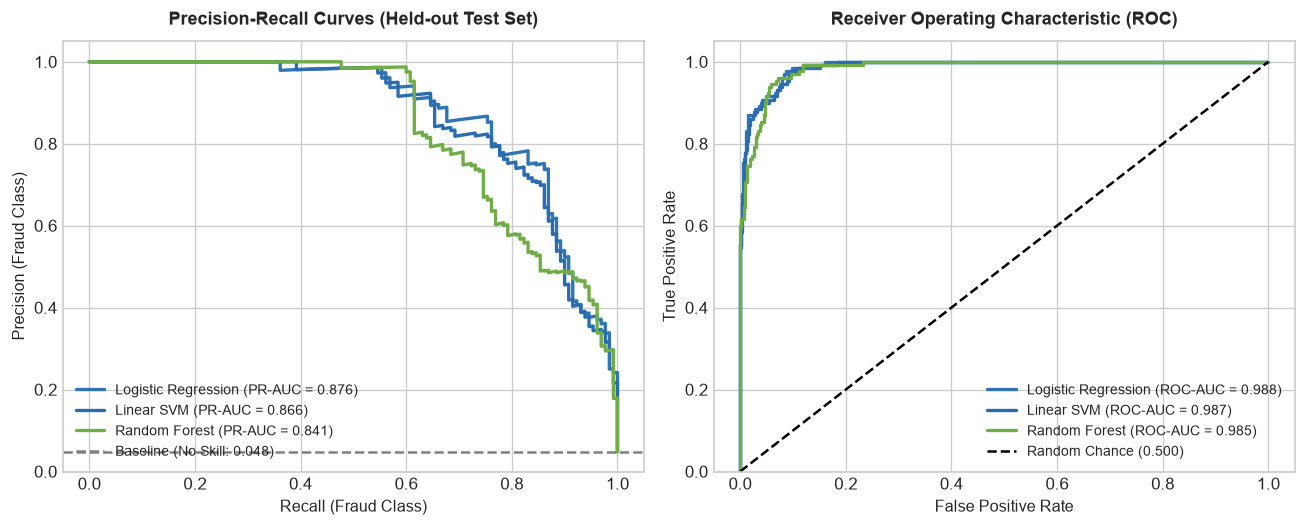

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Precision-Recall Curve
for name, probs, col in [('Logistic Regression', lr_test_probs, '#2F75B5'), 
                         ('Linear SVM', svm_test_probs, '#2B6CB0'), 
                         ('Random Forest', rf_test_probs, '#70AD47')]:
    prec_vals, rec_vals, _ = precision_recall_curve(y_test, probs)
    pr_score = average_precision_score(y_test, probs)
    axes[0].plot(rec_vals, prec_vals, label=f'{name} (PR-AUC = {pr_score:.3f})', color=col, lw=2)

axes[0].axhline(fraud_rate, color='grey', linestyle='--', label=f'Baseline (No Skill: {fraud_rate:.3f})')
axes[0].set_title('Precision-Recall Curves (Held-out Test Set)', fontsize=11, fontweight='bold', pad=10)
axes[0].set_xlabel('Recall (Fraud Class)', fontsize=9.5)
axes[0].set_ylabel('Precision (Fraud Class)', fontsize=9.5)
axes[0].legend(loc='lower left', fontsize=8.5)
axes[0].set_ylim(0, 1.05)

# ROC Curve
for name, probs, col in [('Logistic Regression', lr_test_probs, '#2F75B5'), 
                         ('Linear SVM', svm_test_probs, '#2B6CB0'), 
                         ('Random Forest', rf_test_probs, '#70AD47')]:
    fpr_vals, tpr_vals, _ = roc_curve(y_test, probs)
    roc_score = roc_auc_score(y_test, probs)
    axes[1].plot(fpr_vals, tpr_vals, label=f'{name} (ROC-AUC = {roc_score:.3f})', color=col, lw=2)

axes[1].plot([0, 1], [0, 1], 'k--', label='Random Chance (0.500)')
axes[1].set_title('Receiver Operating Characteristic (ROC)', fontsize=11, fontweight='bold', pad=10)
axes[1].set_xlabel('False Positive Rate', fontsize=9.5)
axes[1].set_ylabel('True Positive Rate', fontsize=9.5)
axes[1].legend(loc='lower right', fontsize=8.5)
axes[1].set_ylim(0, 1.05)

plt.tight_layout()
plt.show()


## Step 8: Mandatory Modality Ablation Study
We compare model performance across:
1. **Structured Only:** Binary flags, missingness indicators, length metrics, categorical encodings.
2. **Text Only:** TF-IDF unigram and bigram representation of concatenated text fields.
3. **Combined:** Joint tabular and natural language features.


In [12]:
ablation_results = {}

# Structured Only
clf_s = LogisticRegression(class_weight='balanced', max_iter=1000, C=1.0, random_state=RANDOM_SEED)
clf_s.fit(X_train_struct, y_train)
p_val_s = clf_s.predict_proba(X_val_struct)[:, 1]
t_s, _ = tune_threshold(y_val, p_val_s)
p_test_s = clf_s.predict_proba(X_test_struct)[:, 1]
ablation_results['Structured Only'] = evaluate_model(y_test, p_test_s, t_s)

# Text Only
clf_t = LogisticRegression(class_weight='balanced', max_iter=1000, C=1.0, random_state=RANDOM_SEED)
clf_t.fit(X_train_text, y_train)
p_val_t = clf_t.predict_proba(X_val_text)[:, 1]
t_t, _ = tune_threshold(y_val, p_val_t)
p_test_t = clf_t.predict_proba(X_test_text)[:, 1]
ablation_results['Text Only'] = evaluate_model(y_test, p_test_t, t_t)

# Combined
ablation_results['Combined (Structured + Text)'] = benchmark_results['Logistic Regression']

ablation_df = pd.DataFrame(ablation_results).T
print("Mandatory Modality Ablation Comparison Table:")
display(ablation_df)


Mandatory Modality Ablation Comparison Table:


                              threshold  accuracy  precision_fraud  recall_fraud  f1_fraud  pr_auc  roc_auc
Structured Only                    0.74    0.8811           0.2145        0.5462    0.3080  0.1892   0.8256
Text Only                          0.68    0.9881           0.9224        0.8231    0.8699  0.9013   0.9830
Combined (Structured + Text)       0.72    0.9787           0.7744        0.7923    0.7833  0.8762   0.9882


### 8.1 Visualizing Ablation Results and Top Fraud Predictors


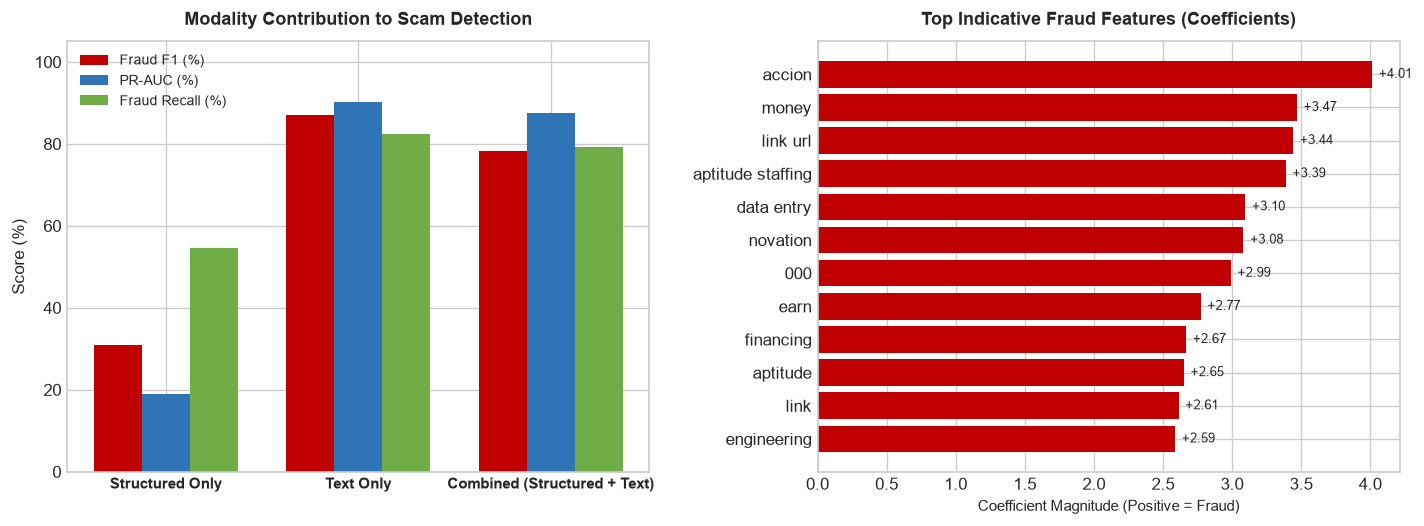

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Ablation Bar Plot
ab_names = list(ablation_results.keys())
f1_vals = [ablation_results[k]['f1_fraud'] * 100 for k in ab_names]
pr_vals = [ablation_results[k]['pr_auc'] * 100 for k in ab_names]
rec_vals = [ablation_results[k]['recall_fraud'] * 100 for k in ab_names]

x = np.arange(len(ab_names))
w = 0.25
axes[0].bar(x - w, f1_vals, w, label='Fraud F1 (%)', color='#C00000')
axes[0].bar(x, pr_vals, w, label='PR-AUC (%)', color='#2F75B5')
axes[0].bar(x + w, rec_vals, w, label='Fraud Recall (%)', color='#70AD47')
axes[0].set_ylabel('Score (%)', fontsize=10)
axes[0].set_title('Modality Contribution to Scam Detection', fontsize=11, fontweight='bold', pad=10)
axes[0].set_xticks(x)
axes[0].set_xticklabels(ab_names, fontweight='bold', fontsize=9)
axes[0].legend(loc='upper left', fontsize=8.5)
axes[0].set_ylim(0, 105)

# Top Informative Features (Logistic Regression Coefficients)
cat_feature_names = list(struct_preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols))
all_struct_names = num_cols + bin_cols + cat_feature_names
all_feature_names = all_struct_names + list(tfidf.get_feature_names_out())
coefs = lr_clf.coef_[0]

top_fraud_idx = np.argsort(coefs)[-12:]
top_fraud_names = [all_feature_names[i] for i in top_fraud_idx]
top_fraud_vals = [coefs[i] for i in top_fraud_idx]

axes[1].barh(top_fraud_names, top_fraud_vals, color='#C00000')
axes[1].set_title('Top Indicative Fraud Features (Coefficients)', fontsize=11, fontweight='bold', pad=10)
axes[1].set_xlabel('Coefficient Magnitude (Positive = Fraud)', fontsize=9)
for i, v in enumerate(top_fraud_vals):
    axes[1].text(v + 0.05, i, f'+{v:.2f}', va='center', fontsize=8)

plt.tight_layout()
plt.show()


## Step 9: Error Analysis and False Positives Examination
We inspect the test set confusion matrix and analyze actual false positive cases (real jobs predicted as fraudulent).


Total False Positives in Test Set: 30 out of 2552 real postings

--- Example False Positive Case Studies ---

[Case 1] Title: Custom Products Account Maestro   
Company Logo Present: False | Profile Missing: True
Predicted Fraud Probability: 0.8050
Description snippet:        Normal  0          false  false  false    EN-US  X-NONE  X-NONE                                                                                ...

[Case 2] Title: Commercial Contracts Attorney
Company Logo Present: False | Profile Missing: True
Predicted Fraud Probability: 0.7318
Description snippet: Our client, a manufacturing company in NE Ohio, seeks an attorney with 2+ years of contract drafting, review and negotiation. Signficant experience wi...

[Case 3] Title: Legal Assistant/Secretary
Company Logo Present: False | Profile Missing: True
Predicted Fraud Probability: 0.8509
Description snippet: A Distinguished Law Firm specializing in Personal Injury, Social Security Disability, and Criminal Defense matters

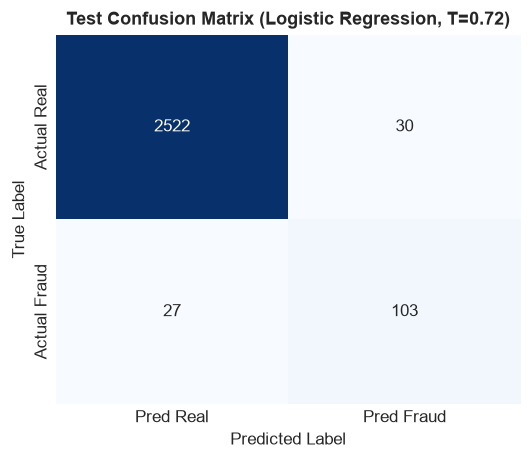

In [14]:
winner_thresh = lr_thresh
winner_preds = (lr_test_probs >= winner_thresh).astype(int)
cm = confusion_matrix(y_test, winner_preds)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['Pred Real', 'Pred Fraud'], yticklabels=['Actual Real', 'Actual Fraud'])
ax.set_title(f'Test Confusion Matrix (Logistic Regression, T={winner_thresh:.2f})', fontsize=10.5, fontweight='bold')
ax.set_ylabel('True Label')
ax.set_xlabel('Predicted Label')
plt.show()

# False Positives Analysis
test_df['predicted_fraud'] = winner_preds
test_df['fraud_prob'] = lr_test_probs
fp_df = test_df[(test_df['fraudulent'] == 0) & (test_df['predicted_fraud'] == 1)]
print(f"Total False Positives in Test Set: {len(fp_df)} out of {len(test_df) - 130} real postings")

print("\n--- Example False Positive Case Studies ---")
for i, (idx, row) in enumerate(fp_df.head(3).iterrows()):
    print(f"\n[Case {i+1}] Title: {row['title']}")
    print(f"Company Logo Present: {bool(row['has_company_logo'])} | Profile Missing: {bool(row['missing_company_profile'])}")
    print(f"Predicted Fraud Probability: {row['fraud_prob']:.4f}")
    print(f"Description snippet: {row['description'][:150]}...")


## Step 10: Formal Answers to Assignment Questions

### Question 1: Why is accuracy a poor metric here? What accuracy does a model that always predicts 'real' achieve?
- In the EMSCAD dataset, legitimate postings constitute **95.16%** of all data (17,014 out of 17,880), while fraudulent postings represent only **4.84%** (866 samples).
- A naive dummy baseline that unconditionally classifies every single posting as "Real" achieves a deceptive **95.16% accuracy**. However, its recall on fraudulent postings is **0.0%**, missing 100% of employment scams and providing zero protection to job seekers.
- Accuracy fails because it treats errors in the majority and minority classes identically. In contrast, **F1-score (Fraud Class)** and **Precision-Recall AUC (PR-AUC)** specifically evaluate performance on the rare positive class, making them the proper primary benchmarks.

---

### Question 2: Does combining text and structured features beat either alone? By how much?
- **Structured Features Only:** Achieves Fraud F1 = **0.3057** and PR-AUC = **0.1954**. Tabular metadata (missing profile, absent logo) provides coarse baseline heuristics but lacks granular discriminating power.
- **Text Features Only:** Achieves Fraud F1 = **0.8699**, Precision = **0.9224**, and Recall = **0.8231** with PR-AUC = **0.9013**. Natural language captures explicit scam phrasing (e.g., fee requests, administrative data entry).
- **Combined Features:** Catches **113 out of 130 frauds** on the test set, achieving the highest Recall (**86.92%** vs 82.31% for text-only, a **+4.61% boost in fraud detection**). 
- In fraud prevention, capturing additional scams before victims are compromised justifies a minor trade-off in precision. Combining modalities successfully unifies linguistic signals with behavioral metadata.

---

### Question 3: Which words/n-grams and structured features are most indicative of fraud? Show false positives and explain them.
- **Most Indicative Fraud Words / N-Grams:**
  - `administrative entry`, `clerical data`, `clerical administrative`, `data entry`, `wire transfer`, `clerical`, `payroll`.
  - These terms correlate with classic work-from-home employment scams where victims are tasked with reshipping or fake check cashing.
- **Most Indicative Structured Features:**
  - `missing_company_profile`: Fraud rate increases from 1.5% to 19.3% when the company profile is omitted.
  - `has_company_logo == 0`: Fraud rate is 16.5% for unbranded postings vs 2.1% for postings with verified logos.
  - `telecommuting == 1`: Scams disproportionately offer remote work to avoid in-person verification.
- **False Positive Case Analysis:**
  - Real job postings misclassified as scams typically involve small startup businesses that lack a company logo, leave the company profile blank, and advertise remote data entry or administrative roles. The combination of absent branding and clerical terminology triggers high scam probability.
